## Single Species Model - Bio Only

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Dataset
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, precision_recall_curve, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
from pathlib import Path
import random
import json
import csv
from collections import Counter
plt.style.use('ggplot')

In [32]:
# Global vars single species
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 0
INPUT_COLS = ['Annual Mean Temperature',
            'Temperature Seasonality',
            'Max Temperature of Warmest Month',
            'Min Temperature of Coldest Month',
            'Annual Precipitation',
            'Precipitation Seasonality',
            'Precipitation of Driest Quarter',
            'Elevation']
NUM_INPUTS = len(INPUT_COLS)
NUM_EPOCHS = 38
LEARNING_RATE = 5e-3
CRITERION = nn.BCEWithLogitsLoss()
BATCH_SIZE = 512
NUM_HIDDEN_LAYERS = 3
HIDDEN_DIM = 128
RESULTS_DIR = Path.cwd()
COMMON_SETTINGS = {
    'seed': SEED, 'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE, 'num_epochs': NUM_EPOCHS,
}
DROPOUT_KEEP = 0.85

### preprocess_species.py

In [33]:
import numpy as np
import pandas as pd
from global_land_mask import globe
import h3

SEED=0
res=4
Abs_per_presence=1

# Load training data
train = np.load('species/species_train.npz')

# Grid- every H3 cell on the globe
grid_cells = [c for r0 in h3.get_res0_cells() for c in h3.cell_to_children(r0, res)]
grid = np.array([h3.cell_to_latlng(c) for c in grid_cells]) # centers
cell_index = {c: i for i, c in enumerate(grid_cells)}
print('Grid cells-', len(grid))

df = pd.DataFrame({'lat': train['train_locs'][:, 0], 'lon': train['train_locs'][:, 1], 'species': train['train_ids'],})
print('Sightings-', len(df))

def near_land(lat, lon, step=.25): # .25 d- about 28km N-S
    near = np.zeros(len(lat), dtype=bool)
    for dlat in (-step, 0, step):
        for dlon in (-step, 0, step):
            clip_lat = np.clip(lat+dlat,-90,90)
            clip_long = np.clip(lon+dlon,-180,180)
            near |= globe.is_land(clip_lat, clip_long)
    return near

# Remove ocean sightings- about 25km from land
df = df[near_land(df['lat'].values, df['lon'].values)].copy()
print('Total after removing ocean sightings-', len(df))
land_cells = np.flatnonzero(near_land(grid[:, 0], grid[:, 1]))
print('Land cells-', len(land_cells))

# Bin- find the H3 cell each sighting falls in
df['cell'] = [cell_index[h3.latlng_to_cell(lat, lon, res)] for lat, lon in zip(df['lat'], df['lon'])]

# Presence only- one row per (cell, species)
presences = df.groupby(['cell', 'species']).size().reset_index(name='n_sightings') # Keep number of sightings
presences['present'] = 1
print('Presences after binning-', len(presences))

# Pseudo-absences- random grid cells (not same as presences but could be in the neighboring cell)
rng = np.random.default_rng(SEED)
absences = []
for species, group in presences.groupby('species'):
    candidates = np.setdiff1d(land_cells, group['cell']) # Pseudo-absences in cells where presences are not there
    picked = rng.choice(candidates, len(group)*Abs_per_presence, replace=False)
    absences.append(pd.DataFrame({'cell': picked, 'species': species, 'present': 0, 'n_sightings': 0}))

data = pd.concat([presences]+absences, ignore_index=True)
print('Pseudo-absences-', (data['present']==0).sum())

# Index for species 0-499
species_index = {taxon: i for i, taxon in enumerate(train['taxon_ids'])}
data['index'] = data['species'].map(species_index)

# Taxonomy class for species
taxonomy = pd.read_csv('species/species_taxonomy.csv')
species_class = dict(zip(taxonomy['taxon_id'], taxonomy['class']))
data['class'] = data['species'].map(species_class)

# Number for each class 
# {0: 'Amphibia', 1: 'Aves', 2: 'Crocodylia', 3: 'Mammalia', 4: 'Squamata', 5: 'Testudines'}
class_names = sorted(taxonomy['class'].unique()) 
class_index = {}
for i, c in enumerate(class_names):
    class_index[c] = i
data['class_id'] = data['class'].map(class_index)

# Features- normalise lat/lon to [-1,1], then sin/cos (SINR paper approach)
def encode(latlon):
    lat = latlon[:,0]/90
    lon = latlon[:,1]/180
    return np.column_stack([np.sin(np.pi*lon), np.cos(np.pi*lon), np.sin(np.pi*lat), np.cos(np.pi*lat)])

X_train = encode(grid[data['cell']])
y_train = data['present'].values
species_train = data['species'].values

# Save
np.savez('species/preprocessed_species.npz', id=data['index'].values, X_train=X_train, y_train=y_train, species_train=species_train, class_id=data['class_id'].values, n_sightings=data['n_sightings'].values, cell_train=data['cell'].values, grid_latlon=grid, grid_cells=np.array(grid_cells), res=res, taxon_ids=train['taxon_ids'])
print('X_train-', X_train.shape, ', y_train-', y_train.shape)

# Usage for models
preprocessed = np.load('species/preprocessed_species.npz')
cols = ['sin_lon', 'cos_lon', 'sin_lat', 'cos_lat']
train_df = pd.DataFrame(preprocessed['X_train'], columns=cols)
train_df['id'] = preprocessed['id']
train_df['class_id'] = preprocessed['class_id']
train_df['species'] = preprocessed['species_train']
train_df['present'] = preprocessed['y_train']
train_df['sightings'] = preprocessed['n_sightings']

X = preprocessed['X_train']
y = preprocessed['y_train']

print(train_df.head())


Grid cells- 288122
Sightings- 272037
Total after removing ocean sightings- 271239
Land cells- 89277
Presences after binning- 69497
Pseudo-absences- 69497
X_train- (138994, 4) , y_train- (138994,)
    sin_lon   cos_lon   sin_lat   cos_lat   id  class_id  species  present  \
0  0.517536  0.855661  0.632448 -0.774602  111         1   145300        1   
1  0.491174  0.871061  0.637845 -0.770165  111         1   145300        1   
2  0.474143  0.880448  0.636310 -0.771434  446         1    12707        1   
3  0.474143  0.880448  0.636310 -0.771434   60         1    12735        1   
4  0.474143  0.880448  0.636310 -0.771434   25         1    13851        1   

   sightings  
0          1  
1          1  
2          2  
3          1  
4          2  


### worldclim_species.py

In [34]:
import numpy as np
import pandas as pd

# Load the climate grid
env_grid = np.load('bioclim_h3_res4.npz')['env_grid']

cols = ['sin_lon', 'cos_lon', 'sin_lat', 'cos_lat']

env_cols = ['Annual Mean Temperature',
            'Temperature Seasonality',
            'Max Temperature of Warmest Month',
            'Min Temperature of Coldest Month',
            'Annual Precipitation',
            'Precipitation Seasonality',
            'Precipitation of Driest Quarter',
            'Elevation']

# Load the preprocessed species data
preprocessed_species = np.load('species/preprocessed_species.npz')

# Make the train df from the preprocessed species data
species_df_bio = pd.DataFrame(preprocessed_species['X_train'], columns=cols)
species_df_bio['cell'] = preprocessed_species['cell_train']
species_df_bio['id'] = preprocessed_species['id']
species_df_bio['present'] = train_df['present']

# climate for each cell
species_df_bio[env_cols] = env_grid[species_df_bio['cell'].values]

# Drop cells with no climate data (ocean)
clean_species = species_df_bio[env_cols].notna().all(axis=1).values
species_df_bio = species_df_bio[clean_species]

X_species_bio = species_df_bio[env_cols].values

# Save
np.savez('preprocessed_species_bio.npz',
         id=preprocessed_species['id'][clean_species],
         X_train=X_species_bio,
         y_train=preprocessed_species['y_train'][clean_species],
         species_train=preprocessed_species['species_train'][clean_species],
         class_id=preprocessed_species['class_id'][clean_species],
         n_sightings=preprocessed_species['n_sightings'][clean_species],
         cell_train=preprocessed_species['cell_train'][clean_species],
         grid_latlon=preprocessed_species['grid_latlon'],
         grid_cells=preprocessed_species['grid_cells'],
         res=preprocessed_species['res'],
         taxon_ids=preprocessed_species['taxon_ids'],
         env_names=np.array(env_cols))
print('X_species_bio-', X_species_bio.shape, ', dropped-', (~clean_species).sum(), 'rows')

X_species_bio- (137968, 8) , dropped- 1026 rows


In [35]:
#Train validation split

#Stratify by species and present
stratify_crit = species_df_bio['id'].astype(str) + '_' + species_df_bio['present'].astype(str)

train_set, valid_set = train_test_split(species_df_bio, test_size=0.25, random_state=SEED, shuffle=True, stratify=stratify_crit)

def inputs_targets(which_df, input_cols=INPUT_COLS):
    
    input_feats = torch.from_numpy(which_df[input_cols].to_numpy()).to(torch.float32)
    species_idx = torch.from_numpy(which_df[['id']].to_numpy()).to(torch.float32)
    inputs = torch.cat([input_feats, species_idx], dim=1).to(DEVICE)
    targets = torch.from_numpy(which_df['present'].to_numpy()).to(torch.float32).to(DEVICE)
    return TensorDataset(inputs, targets)

In [36]:
#data loaders

def make_data_loaders(batch_size=BATCH_SIZE, seed=SEED):
    train_gen = torch.Generator().manual_seed(seed)
    train_data = DataLoader(inputs_targets(train_set), batch_size=batch_size,
                            shuffle=True, generator=train_gen)
    valid_data = DataLoader(inputs_targets(valid_set), batch_size=batch_size,
                                shuffle=False, generator=train_gen)
    return train_data, valid_data
    

In [37]:
class SingleSpeciesMLP(nn.Module):
    def __init__(
            self, num_species=500, num_inputs=NUM_INPUTS,
            num_hidden_layers=NUM_HIDDEN_LAYERS, hidden_dim=HIDDEN_DIM, embedding_dim=32,
            activation=nn.ReLU, dropout_keep=DROPOUT_KEEP):
        
        super().__init__()
        self.num_inputs = num_inputs
        self.num_hidden_layers = num_hidden_layers
        self.hidden_dim = hidden_dim
        self.species_embed = nn.Embedding(num_species, embedding_dim)

        layers = []
        input_dim = num_inputs + embedding_dim
        for _ in range(num_hidden_layers):
            layers.append(nn.Linear(input_dim, hidden_dim))
            if dropout_keep is not None:
                layers.append(nn.Dropout(p=1.0 - dropout_keep))
            layers.append(activation())
            input_dim = hidden_dim

        layers.append(nn.Linear(input_dim, 1))
        self.model = nn.Sequential(*layers)
        for layer in self.model.modules():
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, inputs):
        input_feats = inputs[:, :self.num_inputs]
        species_idx = inputs[:, self.num_inputs].to(torch.long)
        species_emb = self.species_embed(species_idx)
        inputs_emb = torch.cat([input_feats, species_emb], dim=-1)
        return self.model(inputs_emb).squeeze(-1)


In [38]:
def evaluate (model, data_loader, criterion, threshold=0.5):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    # Collect outputs for metrics
    logits_all = []
    targets_all = []
    species_all = []

    with torch.no_grad():
        for inputs, targets in data_loader:
            logits = torch.as_tensor(model(inputs))
            inputs = torch.as_tensor(inputs)
            targets = torch.as_tensor(targets)
            total_loss += criterion(logits, targets).item() * targets.size(0)
            predict = (logits > 0.0).to(targets.dtype)
            total_correct += (predict==targets).sum().item()
            total_examples += targets.size(0)

            logits_all.append(logits)
            targets_all.append(targets)
            species_all.append(inputs[:, -1].to(torch.long))

    probabilities = torch.sigmoid(torch.cat(logits_all)).cpu().numpy()
    true_out = torch.cat(targets_all).cpu().numpy()
    species_ids = torch.cat(species_all).cpu(). numpy()
    predictions = (probabilities >= threshold).astype(np.float32)

    sort = np.argsort(species_ids)
    probabilities_sort = probabilities[sort]
    true_out_sort = true_out[sort]
    species_ids_sort = species_ids[sort]
    predictions_sort = predictions[sort]
    
    unique_species, split_index = np.unique(species_ids_sort, return_index=True)
    probs_by_species = np.split(probabilities_sort, split_index[1:])
    targets_by_species = np.split(true_out_sort, split_index[1:])
    predictions_by_sp = np.split(predictions_sort, split_index[1:])

    auc_per_species = []
    ap_per_species = []
    species_idx_track =[]


    for sp_idx, targs, probs, preds in zip(unique_species, targets_by_species, probs_by_species, predictions_by_sp):
        if len(np.unique(targs)) < 2:
            continue
        species_idx_track.append(sp_idx)
        auc_per_species.append(roc_auc_score(targs, probs))
        ap_per_species.append(average_precision_score(targs, probs))

    macro_auc = float(np.mean(auc_per_species)) # Unweighted average auc
    macro_map = float(np.mean(ap_per_species))  # Unweighted map

    loss_ave = total_loss / total_examples
    accuracy = total_correct / total_examples
    precision, recall, thresholds = precision_recall_curve(true_out, probabilities)
    micro_ap = float(average_precision_score(true_out, probabilities))   # weighted average precision
    curve_data = {
        'auc_per_species': np.asarray(auc_per_species),
        'ap_per_species': np.asarray(ap_per_species),
        'macro_auc': macro_auc,
        'macro_map': macro_map,
        'precision': precision,
        'micro_ap': micro_ap,
        'recall': recall,
        'thresholds': thresholds
    }          
            
    return loss_ave, accuracy, macro_auc, macro_map, curve_data

def train_model(model, train_data, valid_data,
                num_epochs=NUM_EPOCHS, stats_interval=1, learning_rate=LEARNING_RATE,
                criterion=CRITERION, eval_criterion=CRITERION, regularizer=None):
    if criterion is None:
        criterion = nn.BCEWithLogitsLoss()
    if eval_criterion is None:
        eval_criterion = nn.BCEWithLogitsLoss()
    
    optimiser = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    stats =[]
    gradient_history = []

    train_loss, train_acc, train_auc, train_map, _ = evaluate(model, train_data, eval_criterion)
    valid_loss, valid_acc, valid_auc, valid_map, _ = evaluate(model, valid_data, eval_criterion)
    stats.append([train_loss, valid_loss, train_acc, valid_acc, train_auc, valid_auc, train_map, valid_map])

    for epoch in range(1, num_epochs + 1):
        model.train()
        first_batch_gradients = None
        for inputs, targets in train_data:
            optimiser.zero_grad()
            logits = model(inputs)
            loss = criterion(logits, targets)
            if regularizer is not None:
                loss = loss + regularizer(model)
            loss.backward()
            if first_batch_gradients is None:
                first_batch_gradients = [
                    parameter.grad.detach().abs().mean().item()
                    if parameter.grad is not None else 0.0
                    for parameter in model.parameters() if parameter.requires_grad
                ]
            optimiser.step()
        gradient_history.append(first_batch_gradients)

        if epoch % stats_interval==0:
            train_loss, train_acc, train_auc, train_map, _ = evaluate(model, train_data, eval_criterion)
            valid_loss, valid_acc, valid_auc, valid_map, _ = evaluate(model, valid_data, eval_criterion)
            stats.append([train_loss, valid_loss, train_acc, valid_acc, train_auc, valid_auc, train_map, valid_map])

    stats = np.asarray(stats)
    keys = {'train_error' : 0, 'valid_error' : 1,
            'train_acc' : 2, 'valid_acc' : 3,
            'train_auc': 4, 'valid_auc': 5,
            'train_map': 6, 'valid_map': 7
            }

    return stats, keys, np.asarray(gradient_history)
            




In [39]:
def decimal(param):
    return f'{param:.10f}'.rstrip("0").rstrip(".")
    
def name_builder(num_hidden_layers, hidden_dim, label_smoothing=None, dropout_keep=DROPOUT_KEEP, regularizer=None):
    '''Run name creation for naming of files with associated settings'''
    name_parts = [f'single_sp_depth_{num_hidden_layers}', f'width_{hidden_dim}',f'inputs_{NUM_INPUTS}', f'epochs_{NUM_EPOCHS}']

    if dropout_keep is not None:
        name_parts.append(f'dropout_{dropout_keep}')
    if label_smoothing is not None:
        name_parts.append(f'smoothing_{label_smoothing}')
    if regularizer is not None:
        if regularizer.lambda_1 > 0.0 and regularizer.lambda_2 > 0.0:
            name_parts.append(f'elastic_lam1_{decimal(regularizer.lambda_1)}_lam2_{decimal(regularizer.lambda_2)}')
        elif regularizer.lambda_1 == 0.0 and regularizer.lambda_2 > 0.0:
            name_parts.append(f'l2_lambda2_{decimal(regularizer.lambda_2)}')
        elif regularizer.lambda_1 > 0.0 and regularizer.lambda_2 == 0.0:
            name_parts.append(f'l1_lambda1_{decimal(regularizer.lambda_1)}')
            
    
    return "__".join(name_parts) #f'depth{num_hidden_layers}_width{hidden_dim}'

def load_run(name):
    '''Load a saved run'''
    data = np.load(RESULTS_DIR/f'{name}.npz')

    return {'name': name, 'stats': data['stats'], 'gradients': data['gradients'],
            'parameter_names': [str(i) for i in data['parameter_names']], 'config': json.loads(str(data['config']))}
    

In [40]:
train_loader, valid_loader = make_data_loaders(batch_size=BATCH_SIZE, seed=SEED)

In [41]:
def reset_seeds():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)


def run_experiment(num_hidden_layers, hidden_dim, label_smoothing=None, dropout_keep=DROPOUT_KEEP, regularizer=None, overwrite=False):
    """Train a fresh seeded model."""
    lambda_1 = regularizer.lambda_1 if regularizer is not None else 0.0
    lambda_2 = regularizer.lambda_2 if regularizer is not None else 0.0
    
    config = dict(
        COMMON_SETTINGS, num_hidden_layers=num_hidden_layers, hidden_dim=hidden_dim,
        label_smoothing=label_smoothing, dropout_keep=dropout_keep, lambda_1=lambda_1, lambda_2=lambda_2)


    name = name_builder(num_hidden_layers, hidden_dim, label_smoothing, dropout_keep, regularizer)
    result_path = RESULTS_DIR / f'{name}.npz'

    if result_path.exists() and not overwrite:
        existing_result = load_run(name)
        assert existing_result['config'] == json.loads(json.dumps(config)), f'{name}: saved settings differ from those requested. Re-run with overwrite=True to replace'
        print(f'Results loaded for {name}', flush=True)
        return existing_result
              
    
    reset_seeds()
    
    
        
    #train_loader, valid_loader = make_data_loaders(batch_size=BATCH_SIZE, seed=SEED)
    model = SingleSpeciesMLP().to(DEVICE)

    print(f'Training {name} on {DEVICE}: seed={SEED}, epochs={NUM_EPOCHS}', flush=True)
    stats, _, gradients = train_model(
        model, train_loader, valid_loader, num_epochs=NUM_EPOCHS,
        stats_interval=1, learning_rate=LEARNING_RATE, criterion=CRITERION, regularizer=regularizer)
    assert stats.shape == (NUM_EPOCHS + 1, 8) and np.isfinite(stats).all()
    parameter_names = [name for name, parameter in model.named_parameters()
                       if parameter.requires_grad]
    torch.save(model.state_dict(), RESULTS_DIR / f'{name}_weights.pt')
    np.savez(result_path, stats=stats, gradients=gradients,
             parameter_names=np.asarray(parameter_names), config=json.dumps(config, sort_keys=True))
    print(f'Finished {name}: validation accuracy={stats[-1, 3]:.2%}', flush=True)
    print(f'Validation ROC-AUC={stats[-1, 5]:.4f}', flush=True)
    print(f'Validation MAP={stats[-1, 7]:.4f}', flush=True)
    return {'name': name, 'stats': stats, 'gradients': gradients,
            'parameter_names': parameter_names, 'config': config}

def export_table(results, csv_name, parameter_label):
    """Report epoch-100 metrics, with validation accuracy in percent."""
    rows = []
    print(f'{parameter_label:>13} | Val. accuracy (%) | Train CE | Valid CE | Gen Gap | Val AUC | Val MAP |')
    for parameter, result in results.items():
        final = result['stats'][-1]
        row = [parameter, 100 * final[3], final[0], final[1], final[1] - final[0], final[5], final[7]]
        rows.append(row)
        print(f'{parameter:>13} | {row[1]:17.2f} | {row[2]:8.4f} | {row[3]:8.4f} | {row[4]:8.4f} | {row[5]:8.4f} | {row[6]:8.4f} |')
    with (RESULTS_DIR / csv_name).open('w', newline='', encoding='utf-8') as handle:
        writer = csv.writer(handle)
        writer.writerow([parameter_label, 'validation_accuracy_percent',
                         'train_cross_entropy', 'validation_cross_entropy', 'generalisation_gap', 'validation_auc', 'validation_map'])
        writer.writerows(rows)
    return rows


In [42]:
single_species_baseline = run_experiment(num_hidden_layers=NUM_HIDDEN_LAYERS, hidden_dim=HIDDEN_DIM, overwrite=True)


Training single_sp_depth_3__width_128__inputs_8__epochs_38__dropout_0.85 on cuda: seed=0, epochs=38
Finished single_sp_depth_3__width_128__inputs_8__epochs_38__dropout_0.85: validation accuracy=92.84%
Validation ROC-AUC=0.9755
Validation MAP=0.9701


In [43]:
def plot_learning_curves(results, save_prefix=None):
    """Plot stored metrics only; results maps model labels to experiment records."""
    loss_fig, loss_ax = plt.subplots(figsize=(6, 3.8))
    acc_fig, acc_ax = plt.subplots(figsize=(6, 3.8))
    auc_fig, auc_ax = plt.subplots(figsize=(6, 3.8))
    map_fig, map_ax = plt.subplots(figsize=(6, 3.8))
    colours = plt.rcParams['axes.prop_cycle'].by_key()['color']

    for index, (label, result) in enumerate(results.items()):
        values = result['stats']
        epochs = np.arange(1, len(values))  # Row zero is the untrained model.
        colour = colours[index % len(colours)]
        for ax, train_column, valid_column in ((loss_ax, 0, 1), (acc_ax, 2, 3)):
            ax.plot(epochs, values[1:, train_column], color=colour, label=f'{label} (train)')
            ax.plot(epochs, values[1:, valid_column], color=colour,
                    linestyle='--', label=f'{label} (valid)')
        for ax, train_column, valid_column in ((auc_ax, 4, 5), (map_ax, 6, 7)):
                    ax.plot(epochs, values[1:, train_column], color=colour, label=f'{label} (train)')
                    ax.plot(epochs, values[1:, valid_column], color=colour,
                            linestyle='--', label=f'{label} (valid)')
    for ax in (loss_ax, acc_ax):
        ax.set_xlabel('Epoch number')
        ax.legend(fontsize=9, ncol=2)
    for ax in (auc_ax, map_ax):
            ax.set_xlabel('Epoch number')
            ax.legend(fontsize=9, ncol=2)
    loss_ax.set_ylabel('BCE Logit loss')
    acc_ax.set_ylabel('Accuracy')
    auc_ax.set_ylabel('AUC')
    map_ax.set_ylabel('MAP')
    loss_fig.tight_layout()
    acc_fig.tight_layout()
    auc_fig.tight_layout()
    map_fig.tight_layout()
    if save_prefix is not None:
        save_prefix = Path(save_prefix)
        save_prefix.parent.mkdir(parents=True, exist_ok=True)
        loss_fig.savefig(f'{save_prefix}_loss.png', dpi=300, bbox_inches='tight')
        acc_fig.savefig(f'{save_prefix}_accuracy.png', dpi=300, bbox_inches='tight')
        auc_fig.savefig(f'{save_prefix}_auc.png', dpi=300, bbox_inches='tight')
        map_fig.savefig(f'{save_prefix}_map.png', dpi=300, bbox_inches='tight')
    return loss_fig, loss_ax, acc_fig, acc_ax, auc_fig, auc_ax, map_fig, map_ax




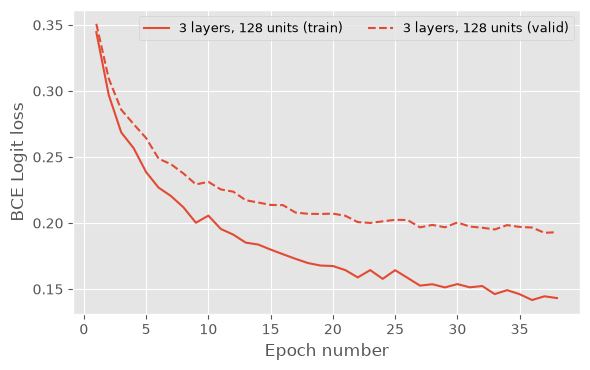

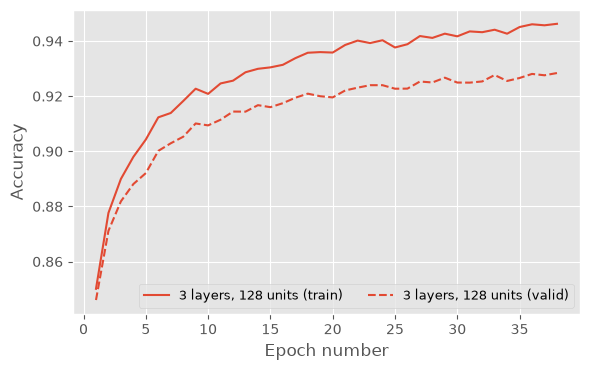

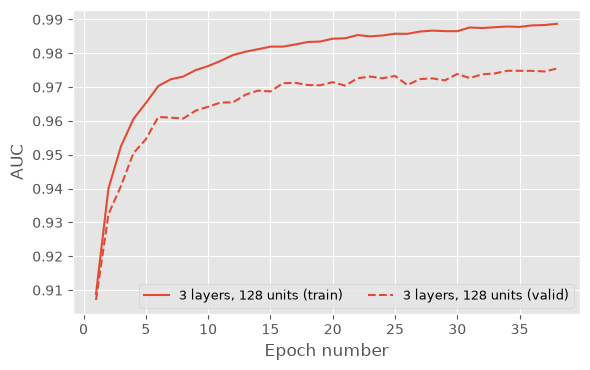

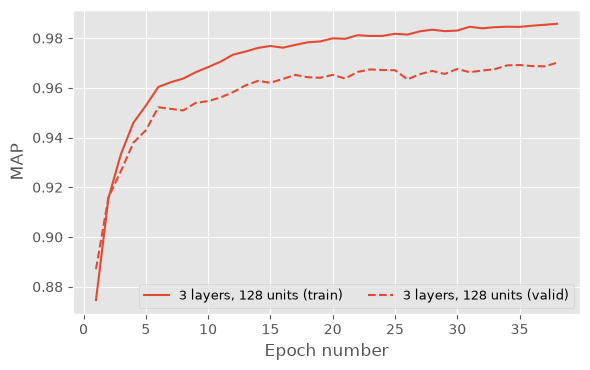

In [44]:
fig_1, ax_1, fig_2, ax_2, fig_3, ax_3, fig_4, ax_4 = plot_learning_curves({f'{NUM_HIDDEN_LAYERS} layers, {HIDDEN_DIM} units': single_species_baseline})


In [45]:
# Early stop cirteria for fixed network capacity - peak map
saved_full_run = np.load('single_sp_depth_3__width_128__inputs_8__epochs_50__dropout_0.85.npz')
map_history = saved_full_run['stats'][1:, 7]
peak_map = np.max(map_history)
peak_map_epoch = np.argmax(map_history) + 1

print(f'Peak Validation MAP: {peak_map}')
print(f'At Epoch: {peak_map_epoch}')

Peak Validation MAP: 0.9700825228215082
At Epoch: 38


In [47]:
# Thesholds optimised using TSS (true skill statistic = true pos rate - false pos rate)

model = SingleSpeciesMLP().to(DEVICE)
model.load_state_dict(torch.load(RESULTS_DIR / f"single_sp_depth_3__width_128__inputs_8__epochs_38__dropout_0.85_weights.pt", map_location=DEVICE))

def optimise_thresholds_single():
    model.eval()
    device = DEVICE

    probs_all = []
    targs_all = []
    species_all = []

    for inputs, targets in valid_loader:
        inputs = inputs.to(device)
        probs_all.append(torch.sigmoid(model(inputs)).cpu().detach().numpy().reshape(-1))
        targs_all.append(targets.cpu().numpy().reshape(-1))
        species_all.append(inputs[:, -1].to(torch.long).cpu().numpy().reshape(-1))

    targs_valid = np.concatenate(targs_all)
    probs_valid = np.concatenate(probs_all)
    species_valid = np.concatenate(species_all)

    thresholds = np.full(500, 0.5)
    for species in range(500):
        mask = (species_valid == species)
        targs = targs_valid[mask]
        probs = probs_valid[mask]
        if (targs == 1).sum() <3 or (targs == 0).sum() < 3:
            continue

        false_pos_rate, true_pos_rate, threshold = roc_curve(targs, probs)
        true_skill_stat = true_pos_rate - false_pos_rate
        thresh_idx = int(np.argmax(true_skill_stat))
        if true_skill_stat[thresh_idx] > 0 and np.isfinite(threshold[thresh_idx]):
            thresholds[species] = threshold[thresh_idx]
    
    return thresholds

thresholds = optimise_thresholds_single()


        
    

In [48]:
val_inputs, val_targets = valid_loader.dataset.tensors
val_inputs_np = val_inputs.cpu().numpy()
val_targets_np = val_targets.cpu().numpy()
species_id = val_inputs_np[:, -1]
# Trained model inference

def single_species_predict_valid(model, input, batch_size=1024):
    model.eval()
    device=DEVICE
    examples = len(input)
    probs = []

    with torch.no_grad():
        for i in range(0, examples, batch_size):
                input_tens = torch.as_tensor(input[i : i+batch_size], dtype=torch.float32, device=device)
                probs.append(torch.sigmoid(model(input_tens)).cpu().detach().numpy())
            

    return np.concatenate(probs)


probs_valid = single_species_predict_valid(model, val_inputs_np)


def presence_absence_single(model, inputs, thresholds):
    probs = single_species_predict_valid(model, inputs)
    pres_abs = (probs >= thresholds).astype(int)

    return pres_abs



def single_species_predict_test(model, input, batch_size=1024):
    model.eval()
    device = DEVICE
    examples = len(input)
    probs = np.zeros((examples, 500))
    input_tens = torch.as_tensor(input, dtype=torch.float32, device=DEVICE)
     
    with torch.no_grad():
        for species in range(500):
            species_col = torch.full((examples, 1), species, dtype=torch.float32, device=DEVICE)
            species_in = torch.cat([input_tens, species_col], dim=1)
            species_prob = []
            for i in range(0, examples, batch_size):
                species_prob.append(torch.sigmoid(model(species_in[i : i + batch_size])).cpu().numpy().reshape(-1))
            probs[:, species] = np.concatenate(species_prob)
    return probs

valid_probs = single_species_predict_test(model, val_inputs_np)

# Create targets mask
n_rows = len(val_targets_np)
rows = np.arange(n_rows)
sp_cols = val_inputs_np[:, -1].astype(int)
val_targets_multi = np.zeros((n_rows, 500))
val_mask = np.zeros((n_rows, 500), dtype=bool)
val_targets_multi[rows, sp_cols] = val_targets_np
val_mask[rows, sp_cols] = True
 
          

In [49]:
def per_species_metrics_multi(probs, targets, mask=None):
    stored_metrics = ('roc_auc', 'ave_pre', 'tss', 'sensitivity', 'specificity')
    metrics = {keys: np.full(500, np.nan) for keys in stored_metrics}
    conf_mat_plot = 500 * [None]

    for species in range(500):
        if mask is not None:
            mask_m = mask[:, species].astype(bool)
            targs = targets[mask_m, species].astype(int)
            probs_p = probs[mask_m, species]
        else:
            targs = targets[:, species].astype(int)
            probs_p = probs[:, species]
        if len(np.unique(targs)) < 2:
            continue

        predicts = (probs_p >= thresholds[species]).astype(int)
        conf_mat_plot[species] = ConfusionMatrixDisplay(confusion_matrix(targs, predicts, labels=[1, 0]), display_labels=['Presence = 1', 'Absence = 0'])
        tru_neg, fal_pos, fal_neg, tru_pos = confusion_matrix(targs, predicts, labels=[1, 0]).ravel()

        sensitivity = tru_pos / (tru_pos + fal_neg)
        specificity = tru_neg / (tru_neg + fal_pos)

        
        metrics['roc_auc'][species] = roc_auc_score(targs, probs_p)
        metrics['ave_pre'][species] = average_precision_score(targs, probs_p)
        metrics['tss'][species] = sensitivity + specificity - 1.0
        metrics['sensitivity'][species] = sensitivity
        metrics['specificity'][species] = specificity

    return metrics, conf_mat_plot



5th, 30th, 50th, and 90th percentile probability thresholds for presence: 
 [0.28597066 0.60893949 0.76343393 0.98693876]
----- Macro Stats (averaged over N species, ignores abundance) -------
Validation set Macro ROC-AUC (ignores aabundance): 0.9754760261508375
Validation set Macro Average Precision: 0.9700825228215082
Validation set Macro True Skill Statistic: 0.9005333665769708
Validation set Macro Sensitivity: 0.9460954126680973
Validation set Macro Specificity: 0.9544379539088736


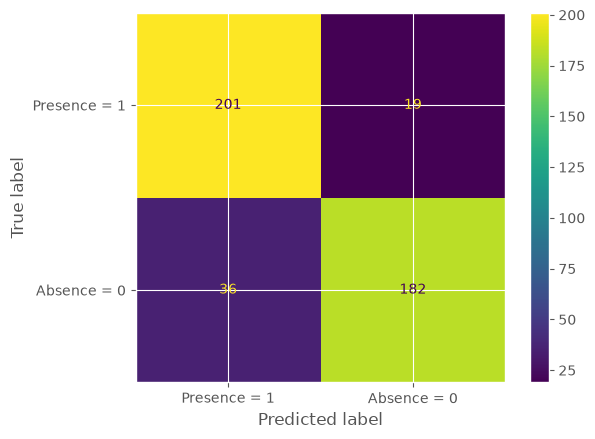

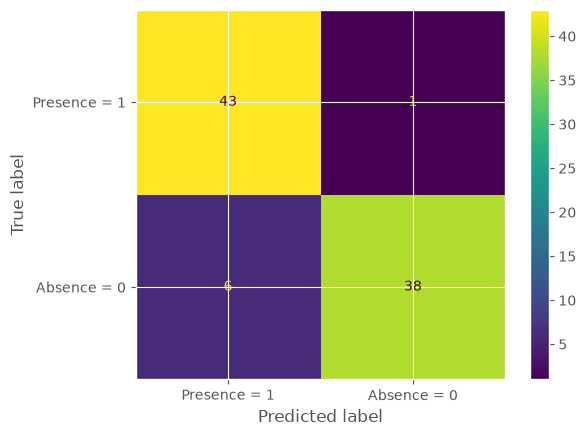

In [50]:
# Validation set stats - location
print(f'5th, 30th, 50th, and 90th percentile probability thresholds for presence: \n {np.percentile(thresholds, [5, 30, 50, 90])}')
valid_metrics, valid_conf_mat = per_species_metrics_multi(valid_probs, val_targets_multi, mask=val_mask)
print(f'----- Macro Stats (averaged over N species, ignores abundance) -------')
print(f'Validation set Macro ROC-AUC (ignores aabundance): {np.nanmean(valid_metrics['roc_auc'])}')
print(f'Validation set Macro Average Precision: {np.nanmean(valid_metrics['ave_pre'])}')
print(f'Validation set Macro True Skill Statistic: {np.nanmean(valid_metrics['tss'])}')
print(f'Validation set Macro Sensitivity: {np.nanmean(valid_metrics['sensitivity'])}')
print(f'Validation set Macro Specificity: {np.nanmean(valid_metrics['specificity'])}')
# Confusion matrix for training set most common (414) and least common (214)
# Stratified so numbers don't confirm rarity
disp_common = valid_conf_mat[414]
disp_common.plot()
disp_rare = valid_conf_mat[214]
disp_rare.plot()

Most common: 414 (appeared 1754 times)
Least common: 244 (appeared 6 times)
{0: 48, 1: 449, 2: 115, 3: 111, 4: 27, 5: 20, 6: 94, 7: 70, 8: 499, 9: 647, 10: 734, 11: 59, 12: 506, 13: 86, 14: 252, 15: 12, 16: 58, 17: 73, 18: 350, 19: 109, 20: 20, 21: 182, 22: 92, 23: 66, 24: 10, 25: 1309, 26: 71, 27: 64, 28: 243, 29: 108, 30: 64, 31: 78, 32: 188, 33: 154, 34: 36, 35: 85, 36: 250, 37: 149, 38: 211, 39: 70, 40: 208, 41: 127, 42: 269, 43: 171, 44: 669, 45: 24, 46: 92, 47: 181, 48: 903, 49: 204, 50: 386, 51: 166, 52: 1621, 53: 137, 54: 40, 55: 68, 56: 107, 57: 363, 58: 114, 59: 128, 60: 1351, 61: 66, 62: 129, 63: 1090, 64: 46, 65: 239, 66: 216, 67: 251, 68: 66, 69: 74, 70: 495, 71: 158, 72: 129, 73: 26, 74: 172, 75: 167, 76: 14, 77: 171, 78: 116, 79: 209, 80: 131, 81: 155, 82: 322, 83: 209, 84: 115, 85: 115, 86: 48, 87: 198, 88: 950, 89: 228, 90: 81, 91: 30, 92: 1435, 93: 46, 94: 480, 95: 1370, 96: 228, 97: 17, 98: 94, 99: 34, 100: 20, 101: 60, 102: 75, 103: 136, 104: 18, 105: 598, 106: 262,

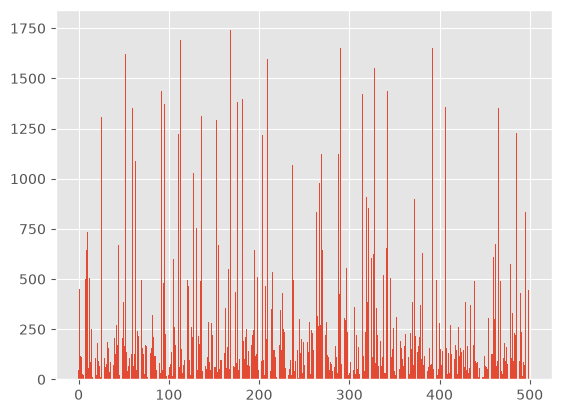

{'mean': 275.936, 'median': 140.0, 'p5': 24.0, 'p10': 36.0, 'p30': 76.69999999999999, 'p50': 140.0, 'p80': 389.4000000000003, 'p90': 669.0}


In [51]:
all_species = []
for entry in species_df_bio["id"]:
    all_species.append(entry)
  
counts = Counter(all_species)

most_common = counts.most_common(1)[0]
least_common = counts.most_common()[-1]

print(f"Most common: {most_common[0]} (appeared {most_common[1]} times)")
print(f"Least common: {least_common[0]} (appeared {least_common[1]} times)")


#least common wavy chameleon - tanzania
#most common wren - americas
sorted_counts = dict(sorted(counts.items(), key=lambda item: item[0]))
print(sorted_counts)
sorted_counts_val = dict(sorted(sorted_counts.items(), key=lambda item: item[1]))
print(sorted_counts_val)
plt.bar((range(len(sorted_counts))), list(sorted_counts.values()), align='center')
plt.show()

def get_dict_stats(data):
  
  if not data:
    raise ValueError("Input dictionary cannot be empty.")

  values = list(data.values())
  percentiles = [5, 10, 30, 50, 80, 90]
  
  pct_values = np.percentile(values, percentiles)

  stats = {
      "mean": float(np.mean(values)),
      "median": float(np.median(values)),
  }
  
  for p, val in zip(percentiles, pct_values):
    stats[f"p{p}"] = float(val)

  return stats

print(get_dict_stats(sorted_counts))
#list(sorted_counts.values())

In [52]:
base_absence_rate = 1.0 - train_df["present"].mean()
print(f"Dummy all-zero accuracy baseline: {base_absence_rate:.2%}")

Dummy all-zero accuracy baseline: 50.00%


### preprocess_test.py

In [53]:
import numpy as np
import h3
import pandas as pd

test = np.load('species/species_test.npz', allow_pickle=True)

# Features- normalise lat/lon to [-1,1], then sin/cos (SINR paper approach)
def encode(latlon):
    lat = latlon[:,0]/90
    lon = latlon[:,1]/180
    return np.column_stack([np.sin(np.pi*lon), np.cos(np.pi*lon), np.sin(np.pi*lat), np.cos(np.pi*lat)])

res = 4
grid_cells = [c for r0 in h3.get_res0_cells() for c in h3.cell_to_children(r0, res)]
cell_index = {c: i for i, c in enumerate(grid_cells)}
cell_test= []
for lat, lon in test['test_locs'].astype(float):
    cell_test.append(cell_index[h3.latlng_to_cell(lat, lon, res)])
cell_test = np.array(cell_test)

X_test = encode(test['test_locs'])
y_test = np.zeros((len(X_test), len(test['taxon_ids'])), dtype=bool)
for i, pos in enumerate(test['test_pos_inds']):
    y_test[pos, i] = 1  # species i present at these locations, 0 elsewhere

print('X_test-', X_test.shape, ', y_test-', y_test.shape, ', cell_test-', cell_test.shape)

# Save
np.savez('species/preprocessed_cells_test.npz', X_test=X_test, y_test=y_test, cell_test=cell_test, test_locs=test['test_locs'], taxon_ids=test['taxon_ids'])

# Usage for models
preprocessed = np.load('species/preprocessed_cells_test.npz')
cols = ['sin_lon', 'cos_lon', 'sin_lat', 'cos_lat']
test_df = pd.DataFrame(preprocessed['X_test'], columns=cols)
test_df['cell'] = preprocessed['cell_test']
test_df['n_species'] = preprocessed['y_test'].sum(axis=1)  # number of species present at each point
test_df['species'] = [np.flatnonzero(row) for row in preprocessed['y_test']]

X = preprocessed['X_test']
y = preprocessed['y_test'].astype(np.float32)  # for NN, 0/1 for each test point for all 500 species

print(test_df.head())

X_test- (288122, 4) , y_test- (288122, 500) , cell_test- (288122,)
    sin_lon   cos_lon   sin_lat   cos_lat    cell  n_species          species
0 -0.112586 -0.993642  0.329871  0.944026  134017          3  [162, 252, 384]
1 -0.299965 -0.953950  0.133619  0.991033  133019          3  [162, 252, 384]
2 -0.208854 -0.977947  0.149162  0.988813  132538          3  [162, 252, 384]
3 -0.178451 -0.983949  0.135019  0.990843  132482          3  [162, 252, 384]
4 -0.181306 -0.983427 -0.216004  0.976393  133649          3  [162, 252, 384]


### worldclim_test.py

In [54]:
import numpy as np
import pandas as pd

# Load the climate grid
env_grid = np.load('bioclim_h3_res4.npz')['env_grid']

# Load the preprocessed test cells
preprocessed_test = np.load('species/preprocessed_cells_test.npz')
X_test = preprocessed_test['X_test']
y_test = preprocessed_test['y_test']
cell_test = preprocessed_test['cell_test']

cols = ['sin_lon',
        'cos_lon',
        'sin_lat',
        'cos_lat'
       ]

# Column names
env_cols = ['Annual Mean Temperature',
            'Temperature Seasonality',
            'Max Temperature of Warmest Month',
            'Min Temperature of Coldest Month',
            'Annual Precipitation',
            'Precipitation Seasonality',
            'Precipitation of Driest Quarter',
            'Elevation']

# Make the test df from the preprocessed test cells
test_df_bio = pd.DataFrame(X_test, columns=cols)
test_df_bio['cell'] = cell_test

# climate for each cell
test_df_bio[env_cols] = env_grid[test_df_bio['cell'].values]

# Drop cells with no climate data (ocean)
clean_test = test_df_bio[env_cols].notna().all(axis=1).values
test_df_bio = test_df_bio[clean_test]

X_test_bio = test_df_bio[env_cols].values
y_test_bio = y_test[clean_test]
cell_test_bio = cell_test[clean_test]

# Save
np.savez('preprocessed_test_bio.npz', X_test=X_test_bio, y_test=y_test_bio, cell_test=cell_test_bio)
print('X_test_bio-', X_test_bio.shape, ', y_test_bio-', y_test_bio.shape)

X_test_bio- (89377, 8) , y_test_bio- (89377, 500)


In [55]:
print(np.unique(np.isnan(X_test_bio)))

[False]


In [57]:
# Run the model on the test set

single_species_test = SingleSpeciesMLP().to(DEVICE)
single_species_test.load_state_dict(torch.load('single_sp_depth_3__width_128__inputs_8__epochs_38__dropout_0.85_weights.pt', map_location=DEVICE))
single_species_test.eval()

def presence_absence_single_test(model, inputs, thresholds):
    probs = single_species_predict_test(model, inputs)
    pres_abs = (probs >= thresholds).astype(int)
    
    return pres_abs, probs
    

# Load test data to X_test (shape (N, NUM_INPUTS)). Ensure no nans (set them to 0)
# Probabilities for species across test set locations

# Binary presence absence for species across test set locations
single_species_test_pres_abs, single_species_test_probs = presence_absence_single_test(single_species_test, X_test_bio, thresholds)

5th, 30th, 50th, and 90th percentile probability thresholds for presence: 
 [0.28597066 0.60893949 0.76343393 0.98693876]
----- Macro Stats (averaged over N species, ignores abundance) -------
Test set Macro ROC-AUC (ignores aabundance): 0.9574691480512502
Test set Macro Average Precision: 0.34726664270267665
Test set Macro True Skill Statistic: 0.6875007878080952
Test set Macro Sensitivity: 0.9433859453600166
Test set Macro Specificity: 0.7441148424480786


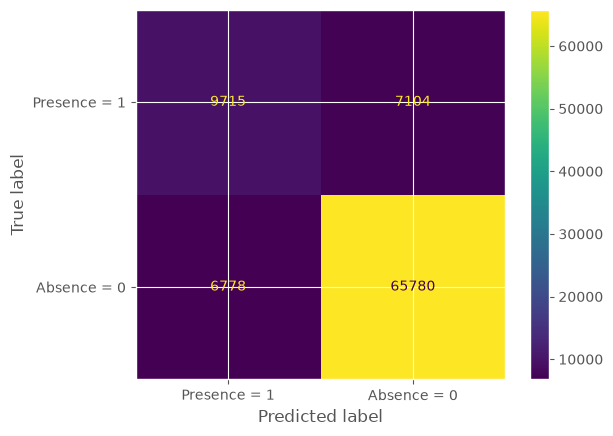

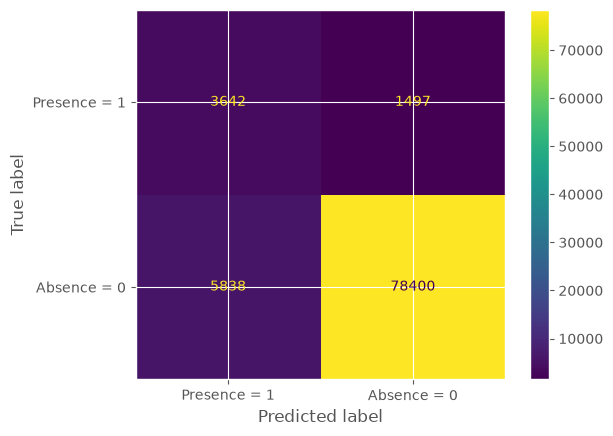

In [58]:
# Test set stats - bio and location
print(f'5th, 30th, 50th, and 90th percentile probability thresholds for presence: \n {np.percentile(thresholds, [5, 30, 50, 90])}')
test_metrics, test_conf_mat = per_species_metrics_multi(single_species_test_probs, y_test_bio)
print(f'----- Macro Stats (averaged over N species, ignores abundance) -------')
print(f'Test set Macro ROC-AUC (ignores aabundance): {np.nanmean(test_metrics['roc_auc'])}')
print(f'Test set Macro Average Precision: {np.nanmean(test_metrics['ave_pre'])}')
print(f'Test set Macro True Skill Statistic: {np.nanmean(test_metrics['tss'])}')
print(f'Test set Macro Sensitivity: {np.nanmean(test_metrics['sensitivity'])}')
print(f'Test set Macro Specificity: {np.nanmean(test_metrics['specificity'])}')
# Confusion matrix for training set most common (414) and least common (214)
# Stratified so numbers don't confirm rarity
disp_common = test_conf_mat[414]
disp_common.plot()
disp_rare = test_conf_mat[214]
disp_rare.plot()